# 07c · Generación de los datasets sintéticos y evaluación final en **test**

**Fase CRISP-DM:** 5. Evaluación. **Es el único notebook que usa la partición de prueba.** Se ejecuta una sola vez, con los modelos ya elegidos en validación (notebooks 06, 07a y 07b); no se cambia ninguna decisión después de ver estos resultados.

**Qué hace**
1. Prepara **test a 128×128** (1530 imágenes reales, 90 por clase) con el mismo redimensionado del notebook 03.
2. Genera un dataset sintético por técnica: **3060 imágenes (180 por clase, igual que train)**, y lo guarda en Drive (`synthetic/`) con su SHA-256.
3. Evalúa cada técnica contra test en el espacio **DINOv2-ViT-L/14**, junto con una **referencia real** (train vs test):
   - **Fidelidad visual:** FD y KD (globales) y KD por clase.
   - **Diversidad:** precisión y recall (Kynkäänniemi et al., 2019), densidad y cobertura (Naeem et al., 2020); globales y por clase.
   - **Fidelidad semántica (sin entrenar clasificadores):** % de imágenes cuyo vecindario k-NN en train corresponde a la clase pedida (equivalente al conteo de imágenes de otra clase de Katsumata et al., 2024), similitud DINO-I con su clase (Malhi et al., 2025) y **% de empaques en espejo** (prueba calibrada).
   - **Memorización:** distancia l2 al vecino más cercano en train, calibrada con la misma distancia de las imágenes reales de test (Stein et al., 2023).
   - **Variabilidad:** intervalos por submuestreo repetido (80 %, `B` repeticiones).
   - **Costo:** horas de entrenamiento y segundos por imagen generada.

**Entorno:** GPU **L4**, versión **2026.07**. Duración ≈ 1–1.5 h (la difusión genera 3060 imágenes).

## Paso 1 · Entorno y parámetros

In [1]:
import sys, os, json, shutil, hashlib, zipfile, time, io, random, re, subprocess, copy, math
from pathlib import Path
from datetime import datetime, timezone
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import scipy.linalg
import matplotlib.pyplot as plt
from PIL import Image
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__,
      "| GPU:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "⚠️ SIN GPU")
SEED = 42
RES = 128
K_PR = int(os.environ.get("K_PR", 5))
FEATURES = os.environ.get("FEATURES", "dinov2")      # 'mock' solo para pruebas sin GPU
AMP = dict(device_type=DEVICE.type, dtype=torch.bfloat16)

Python: 3.12.13 | PyTorch: 2.11.0+cu128 | GPU: NVIDIA L4


In [2]:
%pip install -q diffusers click requests tqdm ninja psutil

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 23.3 MB/s eta 0:00:00


In [3]:
N_FINAL_POR_CLASE = int(os.environ.get("N_FINAL_POR_CLASE", 180))
B = int(os.environ.get("B", 50))                     # repeticiones de submuestreo para la variabilidad
K_SEM = 10                                           # vecinos para la fidelidad semántica
SEED_FINAL = 2026                                    # ruido distinto al usado en la selección
TECNICAS = ["VAE", "GAN", "Difusion"]
# Horas de GPU de entrenamiento (L4). Revisa y corrige con tus registros si difieren.
HORAS_ENTRENAMIENTO = {"VAE": 0.2, "GAN": 17.9, "Difusion": 17.9}

## Paso 2 · Drive y datos de train/val

In [4]:
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/tesis_retail")
    LOCAL_DIR = Path("/content/data")
else:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./tesis_retail")).resolve()
    LOCAL_DIR = Path(os.environ.get("LOCAL_DIR", "./data_local")).resolve()
LOGS = PROJECT_DIR / "logs"
SEL_DIR = PROJECT_DIR / "seleccion"
CKPT = PROJECT_DIR / "checkpoints"
for d in [SEL_DIR, LOCAL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

LOG03 = json.loads((LOGS / "03_piloto.json").read_text())

def cargar_zip(nombre, sha):
    z = LOCAL_DIR / nombre
    if not z.exists():
        shutil.copy2(PROJECT_DIR / "datasets" / nombre, z)
    assert sha256_file(z) == sha, f"⚠️ {nombre} no coincide con el del notebook 03"
    with zipfile.ZipFile(z) as zf:
        lab = dict(json.loads(zf.read("dataset.json"))["labels"])
        nombres = sorted(lab)
        X = np.stack([np.asarray(Image.open(io.BytesIO(zf.read(n))).convert("RGB")) for n in nombres])
    return torch.from_numpy(X).permute(0, 3, 1, 2).contiguous(), torch.tensor([lab[n] for n in nombres])

X_train, Y_train = cargar_zip(LOG03["datasets"]["train_zip"], LOG03["datasets"]["train_sha256"])
X_val, Y_val = cargar_zip(LOG03["datasets"]["val_zip"], LOG03["datasets"]["val_sha256"])
N_CLASSES = int(Y_train.max()) + 1
CLASS_MAP = json.loads((PROJECT_DIR / "manifest" / "class_map.json").read_text())
CLASES = [c for c, _ in sorted(CLASS_MAP.items(), key=lambda kv: kv[1])]
NOMBRE_CORTO = [c.split("-")[1] if c.count("-") >= 2 else c for c in CLASES]
print(f"train {tuple(X_train.shape)} | val {tuple(X_val.shape)} | clases {N_CLASSES} ✔")

Mounted at /content/drive
train (3060, 3, 128, 128) | val (510, 3, 128, 128) | clases 17 ✔


In [5]:
RES_DIR = PROJECT_DIR / "resultados"; SYN_DIR = PROJECT_DIR / "synthetic"
for d in [RES_DIR, SYN_DIR]:
    d.mkdir(parents=True, exist_ok=True)
SEL = {"VAE": json.loads((LOGS / "06_vae_seleccion.json").read_text())["seleccion"]["elegido"],
       "Difusion": json.loads((LOGS / "07a_seleccion_difusion.json").read_text())["elegido"],
       "GAN": json.loads((LOGS / "07b_seleccion_gan.json").read_text())["elegido"]}
print(json.dumps({k: (v if isinstance(v, str) else {kk: v[kk] for kk in v if kk in ("checkpoint", "snapshot", "guia", "kimg", "paso")})
                  for k, v in SEL.items()}, indent=2, ensure_ascii=False))

{
  "VAE": "cvae_ep0450.pt",
  "Difusion": {
    "checkpoint": "ema_0100000.pt",
    "paso": 100000,
    "guia": 2.0
  },
  "GAN": {
    "snapshot": "00000-train128_stylegan-cond-trans:600-1200-auto1-kimg2400/network-snapshot-001900.pkl",
    "kimg": 1900
  }
}


## Paso 3 · Test a 128×128 (primera y única vez que se usa)

In [6]:
LOG02 = json.loads((LOGS / "02_preparacion.json").read_text())
SPLIT_ZIP = LOCAL_DIR / "grocpos_split_v1.zip"
if not SPLIT_ZIP.exists():
    shutil.copy2(PROJECT_DIR / "splits" / "grocpos_split_v1.zip", SPLIT_ZIP)
assert sha256_file(SPLIT_ZIP) == LOG02["zip_split_sha256"], "⚠️ El zip de partición no coincide con el del notebook 02"
with zipfile.ZipFile(SPLIT_ZIP) as zf:
    nombres = sorted(n for n in zf.namelist() if n.startswith("test/") and not n.endswith("/"))
    imgs, labs = [], []
    for n in nombres:
        clase = n.split("/")[1]
        with Image.open(io.BytesIO(zf.read(n))) as im:
            imgs.append(np.asarray(im.convert("RGB").resize((RES, RES), Image.LANCZOS)))
        labs.append(CLASS_MAP[clase])
X_test = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).contiguous(); Y_test = torch.tensor(labs)
print("test:", tuple(X_test.shape), "| por clase:", np.bincount(Y_test.numpy()).tolist())

test: (1530, 3, 128, 128) | por clase: [90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90]


## Paso 4 · Extractor DINOv2 y métricas

In [7]:
import torchvision.transforms.functional as TF
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
if FEATURES == "dinov2":
    dino = torch.hub.load("facebookresearch/dinov2", "dinov2_vitl14").eval().to(DEVICE)
else:
    torch.manual_seed(0)
    dino = nn.Sequential(nn.AdaptiveAvgPool2d(8), nn.Flatten(), nn.Linear(3 * 64, 64)).eval().to(DEVICE)

@torch.no_grad()
def embeddings(x_m11, bs=128):
    # x en [-1, 1], (N,3,128,128) → (N, D) float64. Mismo preprocesamiento que los notebooks 02 y 06.
    out = []
    for i in range(0, len(x_m11), bs):
        x = ((x_m11[i:i + bs].float().cpu() + 1) / 2).clamp(0, 1)
        x = TF.resize(x, [224, 224], interpolation=TF.InterpolationMode.BICUBIC, antialias=True)
        out.append(dino(((x - MEAN) / STD).to(DEVICE)).float().cpu())
    return torch.cat(out).double().numpy()

def a_m11(x_uint8):
    return x_uint8.float() / 127.5 - 1.0

F_VAL = embeddings(a_m11(X_val))
print("Embeddings de validación:", F_VAL.shape)

Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vitl14/dinov2_vitl14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vitl14_pretrain.pth


100%|██████████| 1.13G/1.13G [00:05<00:00, 223MB/s]


Embeddings de validación: (510, 1024)


In [8]:
def fd(a, b):
    mu1, mu2 = a.mean(0), b.mean(0)
    s1, s2 = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    cm = scipy.linalg.sqrtm(s1 @ s2)
    cm = cm[0] if isinstance(cm, tuple) else cm
    if not np.isfinite(cm).all():
        off = np.eye(len(s1)) * 1e-6
        cm = scipy.linalg.sqrtm((s1 + off) @ (s2 + off)); cm = cm[0] if isinstance(cm, tuple) else cm
    return float(((mu1 - mu2) ** 2).sum() + np.trace(s1 + s2 - 2 * cm.real))

def kd(a, b):
    # MMD² insesgado con kernel polinómico (x·y/d + 1)^3 (como KID; Bińkowski et al., 2018)
    d = a.shape[1]
    k = lambda x, y: (x @ y.T / d + 1) ** 3
    kaa, kbb, kab = k(a, a), k(b, b), k(a, b)
    m, n = len(a), len(b)
    return float((kaa.sum() - np.trace(kaa)) / (m * (m - 1)) + (kbb.sum() - np.trace(kbb)) / (n * (n - 1)) - 2 * kab.mean())

def dist(a, b):
    return np.sqrt(np.clip((a ** 2).sum(1)[:, None] + (b ** 2).sum(1)[None, :] - 2 * a @ b.T, 0, None))

def prdc(real, fake, k=K_PR):
    # Precisión/recall (Kynkäänniemi et al., 2019) y densidad/cobertura (Naeem et al., 2020)
    r_rad = np.sort(dist(real, real), 1)[:, k]
    f_rad = np.sort(dist(fake, fake), 1)[:, k]
    d_rf = dist(real, fake)                                   # (n_real, n_fake)
    precision = float((d_rf <= r_rad[:, None]).any(0).mean())
    recall = float((d_rf <= f_rad[None, :]).any(1).mean())
    density = float((d_rf <= r_rad[:, None]).sum(0).mean() / k)
    coverage = float((d_rf.min(1) <= r_rad).mean())
    return {"precision": precision, "recall": recall, "density": density, "coverage": coverage}

def evaluar(real, fake, con_fd=True):
    out = {"KD": kd(real, fake), **prdc(real, fake)}
    if con_fd:
        out["FD"] = fd(real, fake)
    return out

## Paso 5 · Generadores elegidos

In [9]:
# --- VAE (misma arquitectura del notebook 06) ---
LATENTE = 256
def bloque_down(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 4, 2, 1), nn.GroupNorm(8, cout), nn.SiLU())
def bloque_up(cin, cout):
    return nn.Sequential(nn.ConvTranspose2d(cin, cout, 4, 2, 1), nn.GroupNorm(8, cout), nn.SiLU())
class CVAE(nn.Module):
    def __init__(self, n_clases, z=LATENTE, emb=64):
        super().__init__()
        self.z = z; self.emb = nn.Embedding(n_clases, emb)
        self.enc = nn.Sequential(bloque_down(3, 64), bloque_down(64, 128), bloque_down(128, 256),
                                 bloque_down(256, 256), bloque_down(256, 512))
        self.mu = nn.Linear(512 * 16 + emb, z); self.logvar = nn.Linear(512 * 16 + emb, z)
        self.fc = nn.Linear(z + emb, 512 * 16)
        self.dec = nn.Sequential(bloque_up(512, 256), bloque_up(256, 256), bloque_up(256, 128),
                                 bloque_up(128, 64), nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh())
    def decode(self, z, y):
        return self.dec(self.fc(torch.cat([z, self.emb(y)], 1)).view(-1, 512, 4, 4))

@torch.no_grad()
def generar_vae(y, seed):
    ck = torch.load(CKPT / "cvae_cond128_seed42" / "ckpt" / SEL["VAE"], map_location=DEVICE, weights_only=False)
    m = CVAE(N_CLASSES).to(DEVICE); m.load_state_dict(ck["modelo"]); m.eval()
    g = torch.Generator(device=DEVICE).manual_seed(seed); out = []
    for i in range(0, len(y), 256):
        yy = y[i:i + 256].to(DEVICE)
        out.append(m.decode(torch.randn(len(yy), m.z, device=DEVICE, generator=g), yy).float().clamp(-1, 1).cpu())
    return torch.cat(out)

# --- Difusión (misma configuración del notebook 07a) ---
from diffusers import UNet2DModel, DDPMScheduler, DDIMScheduler
sched = DDPMScheduler(num_train_timesteps=1000, beta_schedule="squaredcos_cap_v2")
DDIM_STEPS = json.loads((LOGS / "07a_seleccion_difusion.json").read_text())["ddim_steps"]
@torch.no_grad()
def generar_difusion(y, seed, bs=128):
    ck = torch.load(CKPT / "ddpm_cond128_seed42" / "ema" / SEL["Difusion"]["checkpoint"], map_location="cpu", weights_only=False)
    cfg = ck["config"]
    m = UNet2DModel(sample_size=cfg["res"], in_channels=3, out_channels=3, layers_per_block=2,
                    block_out_channels=tuple(cfg["channels"]),
                    down_block_types=("DownBlock2D", "DownBlock2D", "DownBlock2D", "AttnDownBlock2D", "AttnDownBlock2D"),
                    up_block_types=("AttnUpBlock2D", "AttnUpBlock2D", "UpBlock2D", "UpBlock2D", "UpBlock2D"),
                    num_class_embeds=cfg["n_classes"] + 1)
    m.load_state_dict(ck["ema"]); m = m.eval().to(DEVICE)
    guia, null_idx, out = float(SEL["Difusion"]["guia"]), cfg["n_classes"], []
    for i in range(0, len(y), bs):
        yy = y[i:i + bs].to(DEVICE)
        ddim = DDIMScheduler.from_config(sched.config); ddim.set_timesteps(DDIM_STEPS)
        g = torch.Generator(device=DEVICE).manual_seed(seed + i)
        x = torch.randn(len(yy), 3, RES, RES, device=DEVICE, generator=g)
        for t in ddim.timesteps:
            with torch.autocast(**AMP):
                e = m(torch.cat([x, x]), t, class_labels=torch.cat([yy, torch.full_like(yy, null_idx)])).sample.float()
            e_c, e_u = e.chunk(2)
            x = ddim.step(e_u + guia * (e_c - e_u), t, x).prev_sample
        out.append(x.clamp(-1, 1).cpu())
    return torch.cat(out)

Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


In [10]:
SG_COMMIT = "b8792265ca23c6efd5e1c85c87cf85073c79266d"      # mshahbazi72/transitional-cGAN
SG3_COMMIT = "c233a919a6faee6e36a316ddd4eddababad1adf9"     # NVlabs/stylegan3 (grid_sample_gradfix)
SG_DIR = LOCAL_DIR / "transitional-cGAN"; SG3_DIR = LOCAL_DIR / "stylegan3"

def clonar(url, destino, commit):
    if not destino.exists():
        subprocess.run(["git", "clone", "-q", url, str(destino)], check=True)
    subprocess.run(["git", "-C", str(destino), "checkout", "-q", commit], check=True)
    subprocess.run(["git", "-C", str(destino), "checkout", "-q", "--", "."], check=True)

clonar("https://github.com/mshahbazi72/transitional-cGAN.git", SG_DIR, SG_COMMIT)
clonar("https://github.com/NVlabs/stylegan3.git", SG3_DIR, SG3_COMMIT)

def parchar(ruta, viejo, nuevo):
    s = ruta.read_text(); assert s.count(viejo) == 1, f"{ruta.name}: {viejo[:50]}"; ruta.write_text(s.replace(viejo, nuevo))

parchar(SG_DIR / "dnnlib" / "util.py", "from distutils.util import strtobool",
        "try:\n    from distutils.util import strtobool\nexcept ImportError:\n"
        "    def strtobool(v):\n        return v.lower() in ('y', 'yes', 't', 'true', 'on', '1')")
parchar(SG_DIR / "torch_utils" / "misc.py", "        super().__init__(dataset)\n", "        super().__init__()\n")
s = (SG3_DIR / "torch_utils" / "ops" / "grid_sample_gradfix.py").read_text().replace("from pkg_resources import parse_version\n", "")
s = s.replace("_use_pytorch_1_11_api = parse_version(torch.__version__) >= parse_version('1.11.0a') # Allow prerelease builds of 1.11",
              "_TV = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])\n_use_pytorch_1_11_api = _TV >= (1, 11)")
s = s.replace("_use_pytorch_1_12_api = parse_version(torch.__version__) >= parse_version('1.12.0a') # Allow prerelease builds of 1.12",
              "_use_pytorch_1_12_api = _TV >= (1, 12)")
(SG_DIR / "torch_utils" / "ops" / "grid_sample_gradfix.py").write_text(s)
co = SG_DIR / "torch_utils" / "custom_ops.py"
parchar(co, "            torch.utils.cpp_extension.load(name=module_name, build_directory=build_dir,",
            "            module = torch.utils.cpp_extension.load(name=module_name, build_directory=build_dir,")
parchar(co, "            torch.utils.cpp_extension.load(name=module_name, verbose=verbose_build, sources=sources, **build_kwargs)",
            "            module = torch.utils.cpp_extension.load(name=module_name, verbose=verbose_build, sources=sources, **build_kwargs)")
parchar(co, "        module = importlib.import_module(module_name)\n", "")
os.environ["TORCH_EXTENSIONS_DIR"] = str(LOCAL_DIR / "torch_extensions")
if DEVICE.type == "cuda":
    cc = torch.cuda.get_device_capability(0); os.environ["TORCH_CUDA_ARCH_LIST"] = f"{cc[0]}.{cc[1]}"
sys.path.insert(0, str(SG_DIR))
import dnnlib, legacy

def cargar_gan(pkl):
    with open(pkl, "rb") as f:
        d = legacy.load_network_pkl(f)
    p = float(d["augment_pipe"].p) if d.get("augment_pipe") is not None else float("nan")
    return d["G_ema"].eval().requires_grad_(False).to(DEVICE), p

@torch.no_grad()
def generar_gan(G, y, seed=SEED, bs=256, psi=1.0):
    g = torch.Generator().manual_seed(seed)
    z_all = torch.randn(len(y), G.z_dim, generator=g)
    out = []
    for i in range(0, len(y), bs):
        z = z_all[i:i + bs].to(DEVICE)
        c = F.one_hot(y[i:i + bs], G.c_dim).float().to(DEVICE)
        out.append(G(z, c, truncation_psi=psi, noise_mode="const").float().clamp(-1, 1).cpu())
    return torch.cat(out)
print("Repo transitional-cGAN listo ✔")

Repo transitional-cGAN listo ✔


In [11]:
def generar_gan_final(y, seed):
    G, _ = cargar_gan(CKPT / "transitional_cgan_cond128_seed42" / SEL["GAN"]["snapshot"])
    return generar_gan(G, y, seed=seed)
GENERADORES = {"VAE": generar_vae, "GAN": generar_gan_final, "Difusion": generar_difusion}

## Paso 6 · Generar y guardar los datasets sintéticos
Si el zip de una técnica ya existe en Drive, se carga en vez de regenerarlo (reanudable).

In [12]:
Y_FINAL = torch.arange(N_CLASSES).repeat_interleave(N_FINAL_POR_CLASE)
SINT, SEG_POR_IMG, SHA_SINT = {}, {}, {}

def guardar_zip(x, y, ruta):
    tmp = LOCAL_DIR / ruta.name
    with zipfile.ZipFile(tmp, "w", compression=zipfile.ZIP_STORED) as zf:
        labels = []
        for i, (img, lab) in enumerate(zip(x, y)):
            nombre = f"{int(lab):02d}/sint_{i:05d}.png"
            buf = io.BytesIO()
            Image.fromarray(((img.permute(1, 2, 0).numpy() + 1) * 127.5).round().clip(0, 255).astype(np.uint8)).save(buf, "PNG")
            zf.writestr(nombre, buf.getvalue()); labels.append([nombre, int(lab)])
        zf.writestr("dataset.json", json.dumps({"labels": labels}))
    shutil.copy2(tmp, ruta); return sha256_file(ruta)

def cargar_sint(ruta):
    with zipfile.ZipFile(ruta) as zf:
        lab = json.loads(zf.read("dataset.json"))["labels"]
        X = np.stack([np.asarray(Image.open(io.BytesIO(zf.read(n))).convert("RGB")) for n, _ in lab])
    return a_m11(torch.from_numpy(X).permute(0, 3, 1, 2)), torch.tensor([l for _, l in lab])

meta_path = SYN_DIR / "sinteticos_meta.json"
META = json.loads(meta_path.read_text()) if meta_path.exists() else {}
for tec in TECNICAS:
    ruta = SYN_DIR / f"{tec.lower()}_sint_{len(Y_FINAL)}.zip"
    if ruta.exists() and tec in META:
        SINT[tec], y_chk = cargar_sint(ruta); assert torch.equal(y_chk, Y_FINAL)
        SEG_POR_IMG[tec], SHA_SINT[tec] = META[tec]["seg_por_img"], META[tec]["sha256"]
        print(f"{tec}: cargado desde Drive"); continue
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t0 = time.time(); x = GENERADORES[tec](Y_FINAL, SEED_FINAL)
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    SEG_POR_IMG[tec] = (time.time() - t0) / len(Y_FINAL)
    x = ((x + 1) * 127.5).round().clamp(0, 255) / 127.5 - 1       # misma cuantización a 8 bits que las reales
    SINT[tec] = x
    SHA_SINT[tec] = guardar_zip(x, Y_FINAL, ruta)
    META[tec] = {"zip": ruta.name, "sha256": SHA_SINT[tec], "seg_por_img": SEG_POR_IMG[tec], "n": len(Y_FINAL),
                 "seleccion": SEL[tec], "seed": SEED_FINAL}
    meta_path.write_text(json.dumps(META, indent=2, ensure_ascii=False, default=float))
    print(f"{tec}: {len(x)} imágenes | {SEG_POR_IMG[tec]*1000:.1f} ms/img | {ruta.name}", flush=True)
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

VAE: 3060 imágenes | 2.5 ms/img | vae_sint_3060.zip
Setting up PyTorch plugin "bias_act_plugin"... Done.
Setting up PyTorch plugin "upfirdn2d_plugin"... Done.
GAN: 3060 imágenes | 25.2 ms/img | gan_sint_3060.zip
Difusion: 3060 imágenes | 767.1 ms/img | difusion_sint_3060.zip


## Paso 7 · Embeddings (train, test y sintéticos)

In [13]:
F_TRAIN = embeddings(a_m11(X_train)); F_TEST = embeddings(a_m11(X_test))
F_SINT = {tec: embeddings(SINT[tec]) for tec in TECNICAS}
YTR, YTE, YS = Y_train.numpy(), Y_test.numpy(), Y_FINAL.numpy()
CONJUNTOS = {"Real (train)": (F_TRAIN, YTR), **{tec: (F_SINT[tec], YS) for tec in TECNICAS}}
print({k: v[0].shape for k, v in CONJUNTOS.items()}, "| test", F_TEST.shape)

{'Real (train)': (3060, 1024), 'VAE': (3060, 1024), 'GAN': (3060, 1024), 'Difusion': (3060, 1024)} | test (1530, 1024)


## Paso 8 · Fidelidad visual y diversidad (globales, con variabilidad)
Cada fila se compara con **test**. La fila *Real (train)* es la referencia: lo mejor alcanzable con estos datos.
Intervalo = percentiles 2.5–97.5 de `B` submuestreos al 80 % (sin reemplazo, para no crear duplicados que distorsionen los vecinos k-NN).

In [14]:
rng = np.random.default_rng(SEED)
def submuestreo(real, fake, frac=0.8):
    ir = rng.choice(len(real), int(frac * len(real)), replace=False)
    i_f = rng.choice(len(fake), int(frac * len(fake)), replace=False)
    return evaluar(real[ir], fake[i_f])

filas = []
for nombre, (Fs, _) in CONJUNTOS.items():
    punto = evaluar(F_TEST, Fs)
    reps = pd.DataFrame([submuestreo(F_TEST, Fs) for _ in range(B)])
    fila = {"conjunto": nombre}
    for m in ["FD", "KD", "precision", "recall", "density", "coverage"]:
        fila[m] = punto[m]; fila[m + "_lo"] = reps[m].quantile(.025); fila[m + "_hi"] = reps[m].quantile(.975)
    filas.append(fila); print(f"{nombre}: FD {punto['FD']:.1f} | KD {punto['KD']:.4f} | P {punto['precision']:.3f} | "
                              f"R {punto['recall']:.3f} | D {punto['density']:.3f} | C {punto['coverage']:.3f}", flush=True)
GLOBAL = pd.DataFrame(filas).set_index("conjunto")
GLOBAL.round(4)

Real (train): FD 65.3 | KD -0.0106 | P 0.934 | R 0.929 | D 1.042 | C 0.998


/tmp/ipykernel_416/1800844862.py:4: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cm = scipy.linalg.sqrtm(s1 @ s2)


VAE: FD 2935.8 | KD 12.8055 | P 0.000 | R 0.000 | D 0.000 | C 0.000
GAN: FD 1583.3 | KD 4.5408 | P 0.001 | R 0.000 | D 0.000 | C 0.001


/tmp/ipykernel_416/1800844862.py:4: LinAlgWarning: Matrix is singular. The result might be inaccurate or the array might not have a square root.
  cm = scipy.linalg.sqrtm(s1 @ s2)


Difusion: FD 712.3 | KD 1.8075 | P 0.251 | R 0.421 | D 0.108 | C 0.260


,FD,FD_lo,FD_hi,KD,KD_lo,KD_hi,precision,precision_lo,precision_hi,recall,recall_lo,recall_hi,density,density_lo,density_hi,coverage,coverage_lo,coverage_hi
conjunto,,,,,,,,,,,,,,,,,,
Real (train),65.3467,79.6197,83.9945,-0.0106,-0.0127,-0.0071,0.9343,0.9228,0.9383,0.9288,0.9133,0.9310,1.0422,1.0197,1.0821,0.9980,0.9953,1.0000
VAE,2935.7540,2938.4715,2953.4248,12.8055,12.7289,12.8787,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
GAN,1583.3008,1587.6430,1602.8094,4.5408,4.5023,4.5794,0.0007,0.0000,0.0132,0.0000,0.0000,0.0000,0.0001,0.0000,0.0026,0.0007,0.0000,0.0008
Difusion,712.3141,720.9479,743.9275,1.8075,1.7725,1.8552,0.2507,0.2544,0.2858,0.4209,0.4395,0.4949,0.1076,0.1095,0.1290,0.2601,0.2731,0.3130


## Paso 9 · Por clase (fidelidad visual y diversidad)
Por clase hay 90 reales de test y 180 sintéticas: se reporta **KD** (insesgada) y precisión/recall/cobertura. FD por clase **no** se reporta: con 90 muestras en 1024 dimensiones es inestable (Benny et al., 2021 advierten lo mismo para WCFID).

In [15]:
filas = []
for nombre, (Fs, ys) in CONJUNTOS.items():
    for c in range(N_CLASSES):
        r, f = F_TEST[YTE == c], Fs[ys == c]
        filas.append({"conjunto": nombre, "clase": NOMBRE_CORTO[c], "KD": kd(r, f), **prdc(r, f)})
POR_CLASE = pd.DataFrame(filas)
tabla_kd = POR_CLASE.pivot(index="clase", columns="conjunto", values="KD")[list(CONJUNTOS)]
tabla_rec = POR_CLASE.pivot(index="clase", columns="conjunto", values="recall")[list(CONJUNTOS)]
print("KD por clase (↓):"); display(tabla_kd.round(4))
print("Recall por clase (↑):"); display(tabla_rec.round(3))

KD por clase (↓):


conjunto,Real (train),VAE,GAN,Difusion
clase,,,,
areilSurf,0.0103,25.8401,16.6479,5.1906
blueBandButter,-0.0351,23.1148,15.3335,5.9922
dairyMilk,-0.0498,21.7216,19.8051,5.6527
laysFrenchCheese,-0.0459,27.7520,21.5336,4.1226
lemonMax,0.0153,22.7249,14.9515,5.5996
lifebouyShampoo,-0.0492,25.3220,16.8142,5.7061
lipton,0.1272,18.8989,14.9149,4.2829
luxRed,-0.0252,21.5100,14.2626,8.0670
milkPack,-0.0522,24.2069,23.6819,8.3984


Recall por clase (↑):


conjunto,Real (train),VAE,GAN,Difusion
clase,,,,
areilSurf,0.911,0.0,0.0,0.256
blueBandButter,0.889,0.0,0.0,0.489
dairyMilk,1.000,0.0,0.0,0.333
laysFrenchCheese,0.944,0.0,0.0,0.444
lemonMax,0.944,0.0,0.0,0.278
lifebouyShampoo,0.933,0.0,0.0,0.500
lipton,0.922,0.0,0.0,0.178
luxRed,0.878,0.0,0.0,0.411
milkPack,0.956,0.0,0.0,0.433


## Paso 10 · Fidelidad semántica (sin entrenar clasificadores)
- **Consistencia de clase k-NN:** cada imagen se asigna a la clase mayoritaria de sus 10 vecinos más cercanos (coseno) entre las imágenes reales de **train**. Se reporta el % asignado a la clase pedida.
- **DINO-I:** similitud coseno media de cada imagen con las imágenes reales de train de su clase.
La fila *Real (test)* es la referencia (imágenes reales nuevas).

In [16]:
def normalizar(Fx):
    return Fx / np.linalg.norm(Fx, axis=1, keepdims=True)
TRn = normalizar(F_TRAIN)
CENTROS = np.stack([TRn[YTR == c].mean(0) for c in range(N_CLASSES)])

def semantica(Fx, y):
    S = normalizar(Fx) @ TRn.T
    vec = np.argsort(-S, axis=1)[:, :K_SEM]
    votos = np.stack([np.bincount(YTR[v], minlength=N_CLASSES) for v in vec])
    pred = np.where((votos == votos.max(1, keepdims=True)).sum(1) > 1, YTR[vec[:, 0]], votos.argmax(1))
    dino_i = (normalizar(Fx) * CENTROS[y]).sum(1)
    return pred, dino_i

SEM_CONJ = {"Real (test)": (F_TEST, YTE), **{tec: (F_SINT[tec], YS) for tec in TECNICAS}}
filas, CONFUSION = [], {}
for nombre, (Fx, y) in SEM_CONJ.items():
    pred, dino_i = semantica(Fx, y)
    acc = pred == y
    reps = [acc[rng.choice(len(acc), int(.8 * len(acc)), replace=False)].mean() for _ in range(B)]
    filas.append({"conjunto": nombre, "consistencia_clase": acc.mean(), "cc_lo": np.quantile(reps, .025), "cc_hi": np.quantile(reps, .975),
                  "DINO_I": dino_i.mean(), "otra_clase_n": int((~acc).sum())})
    CONFUSION[nombre] = pd.crosstab(pd.Series([NOMBRE_CORTO[i] for i in y], name="pedida"),
                                    pd.Series([NOMBRE_CORTO[i] for i in pred], name="asignada"))
    POR_CLASE.loc[POR_CLASE["conjunto"] == nombre, "consistencia_clase"] = [acc[y == c].mean() for c in range(N_CLASSES)] \
        if nombre in CONJUNTOS else None
SEMANTICA = pd.DataFrame(filas).set_index("conjunto")
SEMANTICA.round(4)

,consistencia_clase,cc_lo,cc_hi,DINO_I,otra_clase_n
conjunto,,,,,
Real (test),0.9974,0.9967,0.9990,0.7154,4
VAE,0.0761,0.0728,0.0804,0.0478,2827
GAN,0.6775,0.6706,0.6857,0.3928,987
Difusion,0.8386,0.8321,0.8437,0.5168,494


## Paso 10b · Verificación de texto en espejo (fidelidad semántica)
Las mallas de la GAN muestran empaques con **texto invertido** (filtración del volteo horizontal de ADA). DINOv2 es casi invariante al volteo, así que KD, FD y la consistencia k-NN **no lo detectan**.
Prueba: cada imagen se compara (coseno DINOv2) con las imágenes reales de train de **su clase** y con esas mismas imágenes **volteadas**; si se parece más a las volteadas, se cuenta como "en espejo".
**Calibración** (antes de usarla): con test real (debería dar un % bajo) y con test volteado a propósito (debería dar un % alto). Solo se reporta como métrica si la separación es ≥ 50 puntos; si no, se declara no concluyente y se usa la inspección visual.

In [17]:
TRf = normalizar(embeddings(a_m11(torch.flip(X_train, dims=[3]))))
MASCARA = YTR[None, :]
def espejo(Fx, y):
    n = normalizar(Fx); misma = (MASCARA == y[:, None])
    so = np.where(misma, n @ TRn.T, -9).max(1); sf = np.where(misma, n @ TRf.T, -9).max(1)
    return sf > so
F_TEST_FLIP = embeddings(a_m11(torch.flip(X_test, dims=[3])))
CAL_REAL, CAL_FLIP = espejo(F_TEST, YTE).mean(), espejo(F_TEST_FLIP, YTE).mean()
ESPEJO_VALIDO = (CAL_FLIP - CAL_REAL) >= 0.5
print(f"Calibración: test real {CAL_REAL*100:.1f}% | test volteado {CAL_FLIP*100:.1f}% | "
      f"{'VÁLIDA ✔' if ESPEJO_VALIDO else 'NO concluyente ✗ (usar inspección visual)'}")
filas = [{"conjunto": "Real (test)", "pct_espejo": CAL_REAL * 100}, {"conjunto": "Real (test volteado)", "pct_espejo": CAL_FLIP * 100}]
ESPEJO_CLASE = {}
for tec in TECNICAS:
    e = espejo(F_SINT[tec], YS)
    filas.append({"conjunto": tec, "pct_espejo": e.mean() * 100})
    ESPEJO_CLASE[tec] = [e[YS == c].mean() * 100 for c in range(N_CLASSES)]
ESPEJO = pd.DataFrame(filas).set_index("conjunto")
display(ESPEJO.round(1))
display(pd.DataFrame(ESPEJO_CLASE, index=NOMBRE_CORTO).round(1))

Calibración: test real 42.5% | test volteado 60.1% | NO concluyente ✗ (usar inspección visual)


,pct_espejo
conjunto,
Real (test),42.5
Real (test volteado),60.1
VAE,40.8
GAN,58.0
Difusion,50.9


,VAE,GAN,Difusion
pepsi,23.3,92.2,56.7
yums,26.7,96.7,50.0
nationalKetchup,35.0,39.4,42.8
dairyMilk,13.9,33.9,42.2
tang,38.3,81.7,43.9
areilSurf,79.4,29.4,66.1
milkpackCareem,73.9,92.8,57.2
lipton,10.6,62.8,48.9
lemonMax,85.0,70.6,55.6
milkPack,60.0,7.2,45.0


## Paso 11 · Memorización
Para cada imagen se calcula la distancia l2 (espacio DINOv2) a su vecino más cercano en **train**. La referencia es la misma distancia para las imágenes **reales de test**, que por construcción no son copias (la partición separó los casi duplicados).
Si una técnica tiene muchas más imágenes que test por debajo del percentil 1 o 5 de test, está generando imágenes más cercanas a train que una foto real nueva → señal de copia. Ninguna métrica automática es concluyente (Stein et al., 2023): se acompaña de inspección visual de los pares más cercanos.

In [18]:
def nn_train(Fx):
    d = dist(Fx, F_TRAIN); j = d.argmin(1); return d[np.arange(len(Fx)), j], j
D_TEST, _ = nn_train(F_TEST)
T1, T5 = np.percentile(D_TEST, 1), np.percentile(D_TEST, 5)
filas, NN = [], {}
for tec in TECNICAS:
    d1, j = nn_train(F_SINT[tec]); NN[tec] = (d1, j)
    filas.append({"conjunto": tec, "d1_mediana": np.median(d1), "pct_bajo_p1_test": (d1 < T1).mean() * 100,
                  "pct_bajo_p5_test": (d1 < T5).mean() * 100})
filas.insert(0, {"conjunto": "Real (test)", "d1_mediana": np.median(D_TEST), "pct_bajo_p1_test": 1.0, "pct_bajo_p5_test": 5.0})
MEMO = pd.DataFrame(filas).set_index("conjunto")
print(f"Umbrales (distancia test→train): p1 = {T1:.2f}, p5 = {T5:.2f}")
MEMO.round(2)

Umbrales (distancia test→train): p1 = 8.56, p5 = 10.27


,d1_mediana,pct_bajo_p1_test,pct_bajo_p5_test
conjunto,,,
Real (test),17.15,1.0,5.00
VAE,52.34,0.0,0.00
GAN,40.42,0.0,0.00
Difusion,33.67,0.0,0.03


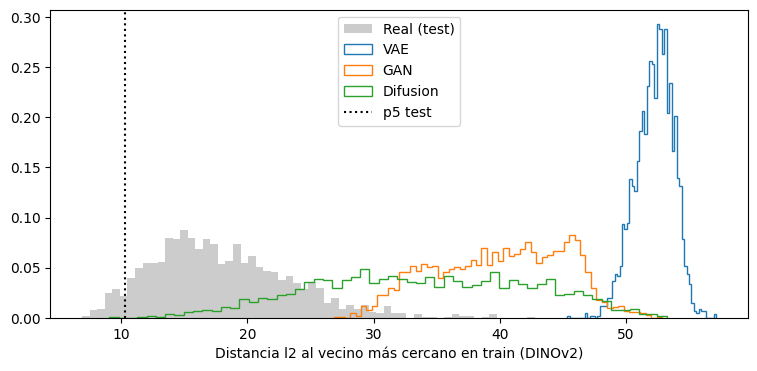

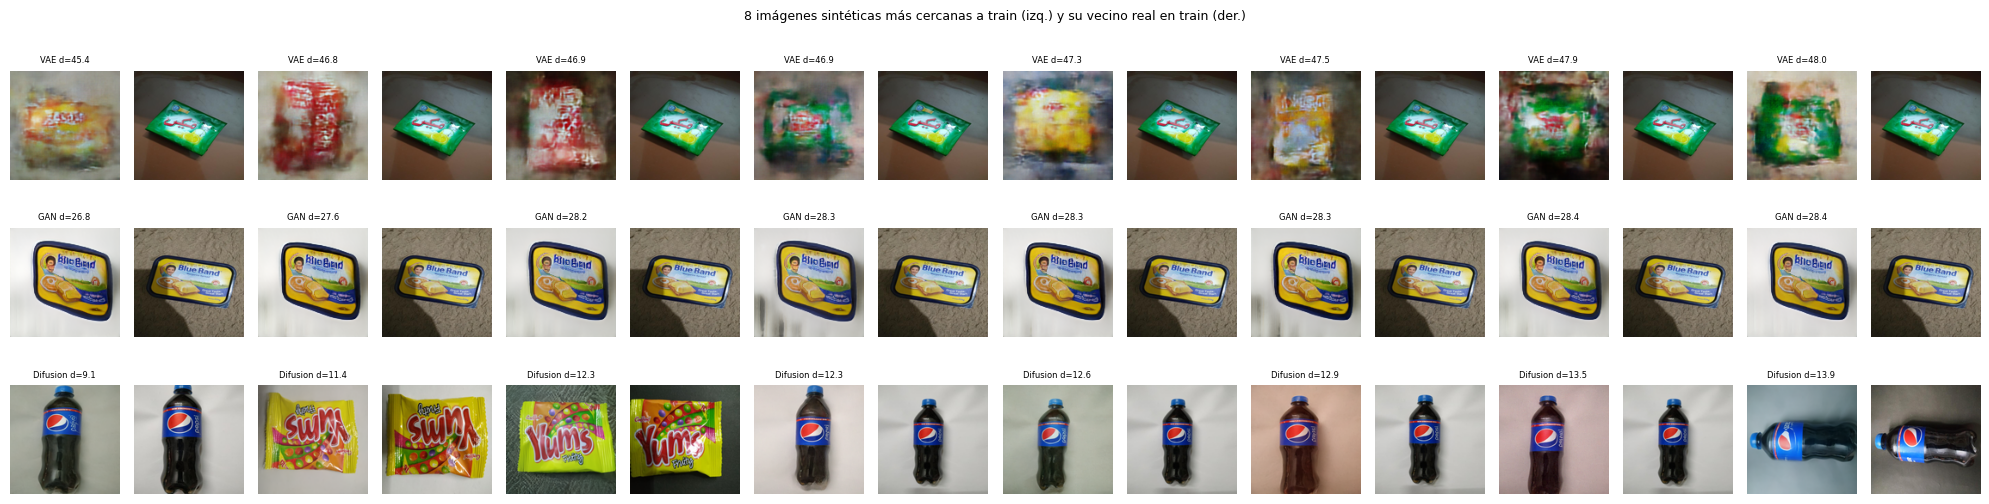

In [19]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(D_TEST, bins=60, density=True, alpha=.4, label="Real (test)", color="gray")
for tec in TECNICAS:
    ax.hist(NN[tec][0], bins=60, density=True, histtype="step", lw=2, label=tec)
ax.axvline(T5, c="k", ls=":", label="p5 test")
ax.set_xlabel("Distancia l2 al vecino más cercano en train (DINOv2)"); ax.legend()
fig.savefig(RES_DIR / "memorizacion_histograma.png", dpi=150, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(len(TECNICAS), 16, figsize=(20, 1.6 * len(TECNICAS) + 0.6), squeeze=False)
for r, tec in enumerate(TECNICAS):
    d1, j = NN[tec]; top = np.argsort(d1)[:8]
    for k, i in enumerate(top):
        axes[r, 2 * k].imshow(((SINT[tec][i].permute(1, 2, 0).numpy() + 1) / 2).clip(0, 1))
        axes[r, 2 * k + 1].imshow(X_train[j[i]].permute(1, 2, 0).numpy())
        axes[r, 2 * k].set_title(f"{tec} d={d1[i]:.1f}", fontsize=6)
    for a in axes[r]: a.axis("off")
fig.suptitle("8 imágenes sintéticas más cercanas a train (izq.) y su vecino real en train (der.)", fontsize=9)
fig.tight_layout(); fig.savefig(RES_DIR / "memorizacion_pares_mas_cercanos.png", dpi=150); plt.show()

## Paso 12 · Tabla final, gráficos y malla comparativa

In [20]:
FINAL = GLOBAL.join(SEMANTICA[["consistencia_clase", "cc_lo", "cc_hi", "DINO_I"]], how="outer")
FINAL.loc["Real (test)", ["consistencia_clase", "DINO_I"]] = SEMANTICA.loc["Real (test)", ["consistencia_clase", "DINO_I"]]
FINAL = FINAL.join(MEMO, how="left").join(ESPEJO, how="left")
FINAL.attrs["espejo_valido"] = bool(ESPEJO_VALIDO)
for tec in TECNICAS:
    FINAL.loc[tec, "horas_entrenamiento_L4"] = HORAS_ENTRENAMIENTO[tec]
    FINAL.loc[tec, "ms_por_imagen"] = SEG_POR_IMG[tec] * 1000
orden = ["Real (train)", "Real (test)", "Real (test volteado)"] + TECNICAS
FINAL = FINAL.reindex([o for o in orden if o in FINAL.index])
FINAL.to_csv(RES_DIR / "metricas_globales.csv"); POR_CLASE.to_csv(RES_DIR / "metricas_por_clase.csv", index=False)
for k, v in CONFUSION.items():
    v.to_csv(RES_DIR / f"confusion_semantica_{k.replace(' ', '_').replace('(', '').replace(')', '')}.csv")
cols = ["FD", "KD", "precision", "recall", "density", "coverage", "consistencia_clase", "DINO_I",
        "pct_espejo", "pct_bajo_p5_test", "horas_entrenamiento_L4", "ms_por_imagen"]
display(FINAL[[c for c in cols if c in FINAL.columns]].round(4))

,FD,KD,precision,recall,density,coverage,consistencia_clase,DINO_I,pct_espejo,pct_bajo_p5_test,horas_entrenamiento_L4,ms_por_imagen
conjunto,,,,,,,,,,,,
Real (train),65.3467,-0.0106,0.9343,0.9288,1.0422,0.9980,NaN,NaN,NaN,NaN,NaN,NaN
Real (test),NaN,NaN,NaN,NaN,NaN,NaN,0.9974,0.7154,42.4837,5.0000,NaN,NaN
VAE,2935.7540,12.8055,0.0000,0.0000,0.0000,0.0000,0.0761,0.0478,40.7516,0.0000,0.2,2.5053
GAN,1583.3008,4.5408,0.0007,0.0000,0.0001,0.0007,0.6775,0.3928,58.0065,0.0000,17.9,25.2310
Difusion,712.3141,1.8075,0.2507,0.4209,0.1076,0.2601,0.8386,0.5168,50.9477,0.0327,17.9,767.1150


In [21]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
nombres = list(CONJUNTOS)
def barras(a, m, titulo):
    v = GLOBAL.loc[nombres, m]; lo = v - GLOBAL.loc[nombres, m + "_lo"]; hi = GLOBAL.loc[nombres, m + "_hi"] - v
    a.bar(nombres, v, yerr=[lo.clip(lower=0), hi.clip(lower=0)], capsize=4, color=["gray", "#4C72B0", "#DD8452", "#55A868"][:len(nombres)])
    a.set_title(titulo); a.tick_params(axis="x", rotation=20)
barras(ax[0], "FD", "FD vs test ↓ (fidelidad visual)")
barras(ax[1], "KD", "KD vs test ↓ (fidelidad visual)")
for n in nombres:
    ax[2].scatter(GLOBAL.loc[n, "recall"], GLOBAL.loc[n, "precision"], s=80, label=n)
ax[2].set_xlabel("recall (diversidad)"); ax[2].set_ylabel("precisión (fidelidad)"); ax[2].set_xlim(0, 1); ax[2].set_ylim(0, 1)
ax[2].legend(fontsize=8); ax[2].set_title("Precisión vs recall")
s = SEMANTICA.loc[list(SEM_CONJ)]
ax[3].bar(s.index, s["consistencia_clase"], yerr=[(s["consistencia_clase"] - s["cc_lo"]).clip(lower=0), (s["cc_hi"] - s["consistencia_clase"]).clip(lower=0)],
          capsize=4, color=["gray", "#4C72B0", "#DD8452", "#55A868"])
ax[3].set_ylim(0, 1); ax[3].set_title("Consistencia de clase k-NN ↑ (semántica)"); ax[3].tick_params(axis="x", rotation=20)
fig.tight_layout(); fig.savefig(RES_DIR / "comparacion_global.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
im = ax[0].imshow(tabla_kd.values, cmap="viridis_r", aspect="auto"); ax[0].set_title("KD por clase ↓")
im2 = ax[1].imshow(tabla_rec.values, cmap="viridis", aspect="auto", vmin=0, vmax=1); ax[1].set_title("Recall por clase ↑")
for a, t in [(ax[0], tabla_kd), (ax[1], tabla_rec)]:
    a.set_yticks(range(len(t.index))); a.set_yticklabels(t.index, fontsize=8)
    a.set_xticks(range(len(t.columns))); a.set_xticklabels(t.columns, rotation=20, fontsize=8)
fig.colorbar(im, ax=ax[0]); fig.colorbar(im2, ax=ax[1])
fig.tight_layout(); fig.savefig(RES_DIR / "metricas_por_clase.png", dpi=150); plt.show()

import torchvision.utils as vutils
filas_img = []
idx_real = np.concatenate([np.where(YTE == c)[0][:2] for c in range(N_CLASSES)])
filas_img.append(a_m11(X_test[idx_real]))
for tec in TECNICAS:
    idx = np.concatenate([np.where(YS == c)[0][:2] for c in range(N_CLASSES)])
    filas_img.append(SINT[tec][idx])
grid = torch.cat([f.view(N_CLASSES, 2, 3, RES, RES).transpose(0, 1).reshape(-1, 3, RES, RES) for f in filas_img])
vutils.save_image((grid + 1) / 2, RES_DIR / "malla_real_vs_tecnicas.png", nrow=N_CLASSES)
print("Filas: real test ×2, luego VAE ×2, GAN ×2, Difusión ×2 | columnas: clases")
if IN_COLAB:
    from IPython.display import Image as IPImage, display
    display(IPImage(filename=str(RES_DIR / "malla_real_vs_tecnicas.png"), width=1100))

Output hidden; open in https://colab.research.google.com to view.

## Paso 13 · Registro

In [22]:
reg = {"fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
       "test": {"n": int(len(Y_test)), "split_sha256": LOG02["zip_split_sha256"], "resize": "Lanczos 128"},
       "seleccion": SEL, "sinteticos": META, "n_por_clase": N_FINAL_POR_CLASE, "B_submuestreos": B, "k_prdc": K_PR, "k_sem": K_SEM,
       "umbrales_memorizacion": {"p1": float(T1), "p5": float(T5)},
       "espejo": {"calibracion_test_real_pct": float(CAL_REAL * 100), "calibracion_test_volteado_pct": float(CAL_FLIP * 100),
                  "valido": bool(ESPEJO_VALIDO), "por_clase": ESPEJO_CLASE},
       "metricas_globales": FINAL.reset_index().to_dict("records"), "horas_entrenamiento": HORAS_ENTRENAMIENTO,
       "features": FEATURES, "versiones": {"python": sys.version.split()[0], "torch": torch.__version__}}
(LOGS / "07c_evaluacion_final.json").write_text(json.dumps(reg, indent=2, ensure_ascii=False, default=float))
print("Resultados en:", RES_DIR)

Resultados en: /content/drive/MyDrive/tesis_retail/resultados


**Al terminar:** desconecta la GPU. Envía al asesor la tabla del Paso 12, los gráficos y las tablas por clase.